In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

DATA_PATH = Path("../week06/data/processed/students_clean.csv")
FIGURE_DIR = Path("charts")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

students = pd.read_csv(DATA_PATH)

required = {"program", "attendance", "final", "weighted_score", "grade"}
print("Dataset Shape:", students.shape)
print("\nRequired Columns Sample:\n", students[sorted(required)].head())
print("\nMissing Values:\n", students[sorted(required)].isna().sum())

Dataset Shape: (10, 17)

Required Columns Sample:
    attendance  final grade program  weighted_score
0        85.0   81.0     B    BSAI            77.7
1        85.0   75.0     B    BSAI            75.5
2        92.0   88.0     B    BSAI            81.6
3        81.0   90.0     B    BSCS            84.7
4        74.0   81.0     C    BSAI            70.1

Missing Values:
 attendance        0
final             0
grade             0
program           0
weighted_score    0
dtype: int64


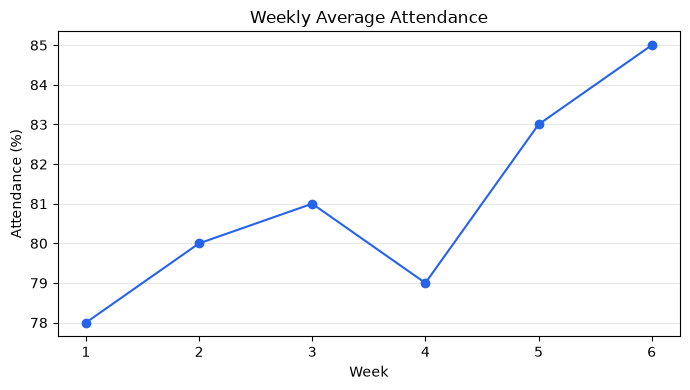

In [3]:
weeks = [1, 2, 3, 4, 5, 6]
average_attendance = [78, 80, 81, 79, 83, 85]

fig1, ax1 = plt.subplots(figsize=(7, 4))
ax1.plot(weeks, average_attendance, marker="o", color="#2563EB")
ax1.set(title="Weekly Average Attendance", xlabel="Week", ylabel="Attendance (%)")
ax1.set_xticks(weeks)
ax1.grid(axis="y", alpha=0.3)
fig1.tight_layout()
plt.show()

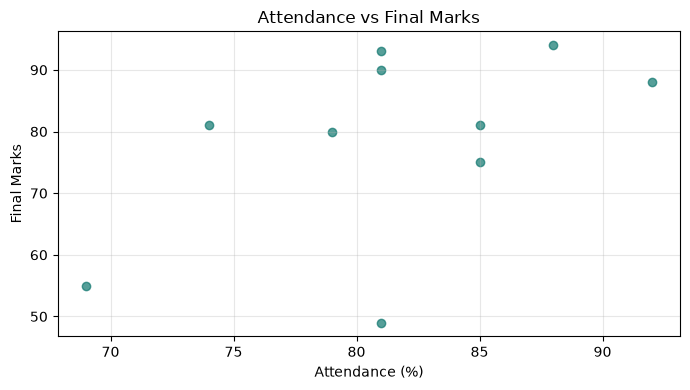

In [4]:
fig2, ax2 = plt.subplots(figsize=(7, 4))
ax2.scatter(students["attendance"], students["final"], alpha=0.7, color="#0F766E")
ax2.set(title="Attendance vs Final Marks", xlabel="Attendance (%)", ylabel="Final Marks")
ax2.grid(alpha=0.3)
fig2.tight_layout()
plt.show()

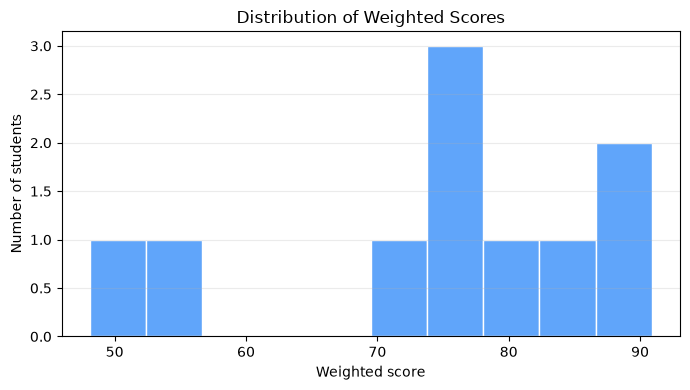

In [5]:
fig3, ax3 = plt.subplots(figsize=(7, 4))
ax3.hist(students["weighted_score"].dropna(), bins=10, color="#60A5FA", edgecolor="white")
ax3.set(title="Distribution of Weighted Scores", xlabel="Weighted score", ylabel="Number of students")
ax3.grid(axis="y", alpha=0.25)
fig3.tight_layout()
plt.show()

C:\Users\HP\AppData\Local\Temp\ipykernel_27084\3627725933.py:2: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax4.boxplot(students["weighted_score"].dropna(), vert=False)


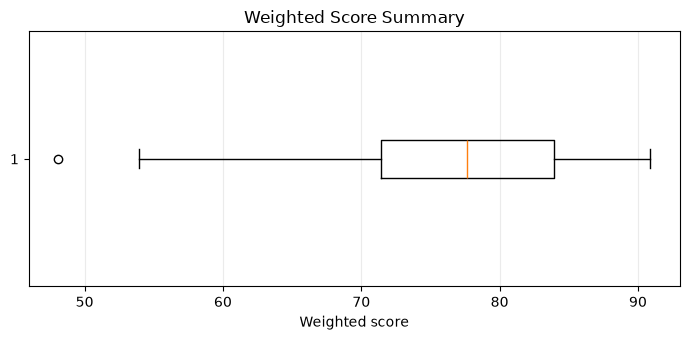

In [6]:
fig4, ax4 = plt.subplots(figsize=(7, 3.5))
ax4.boxplot(students["weighted_score"].dropna(), vert=False)
ax4.set(title="Weighted Score Summary", xlabel="Weighted score")
ax4.grid(axis="x", alpha=0.25)
fig4.tight_layout()
plt.show()

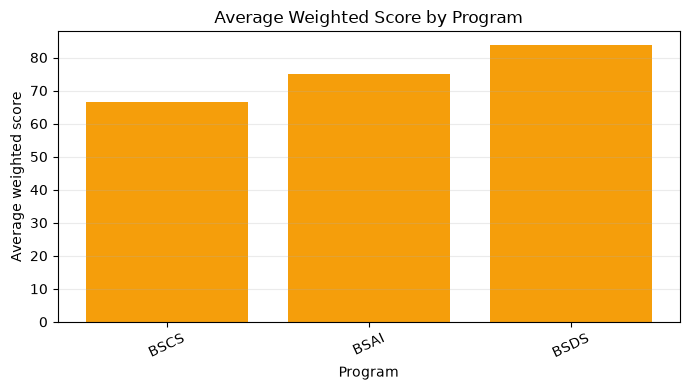

In [7]:
program_scores = students.groupby("program")["weighted_score"].mean().sort_values()

fig5, ax5 = plt.subplots(figsize=(7, 4))
ax5.bar(program_scores.index, program_scores.values, color="#F59E0B")
ax5.set(title="Average Weighted Score by Program", xlabel="Program", ylabel="Average weighted score")
ax5.tick_params(axis="x", rotation=25)
ax5.grid(axis="y", alpha=0.25)
fig5.tight_layout()
plt.show()

C:\Users\HP\AppData\Local\Temp\ipykernel_27084\383713374.py:17: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1, 1].boxplot(students["weighted_score"].dropna(), vert=False)


Dashboard successfully saved to 'figures/' folder!


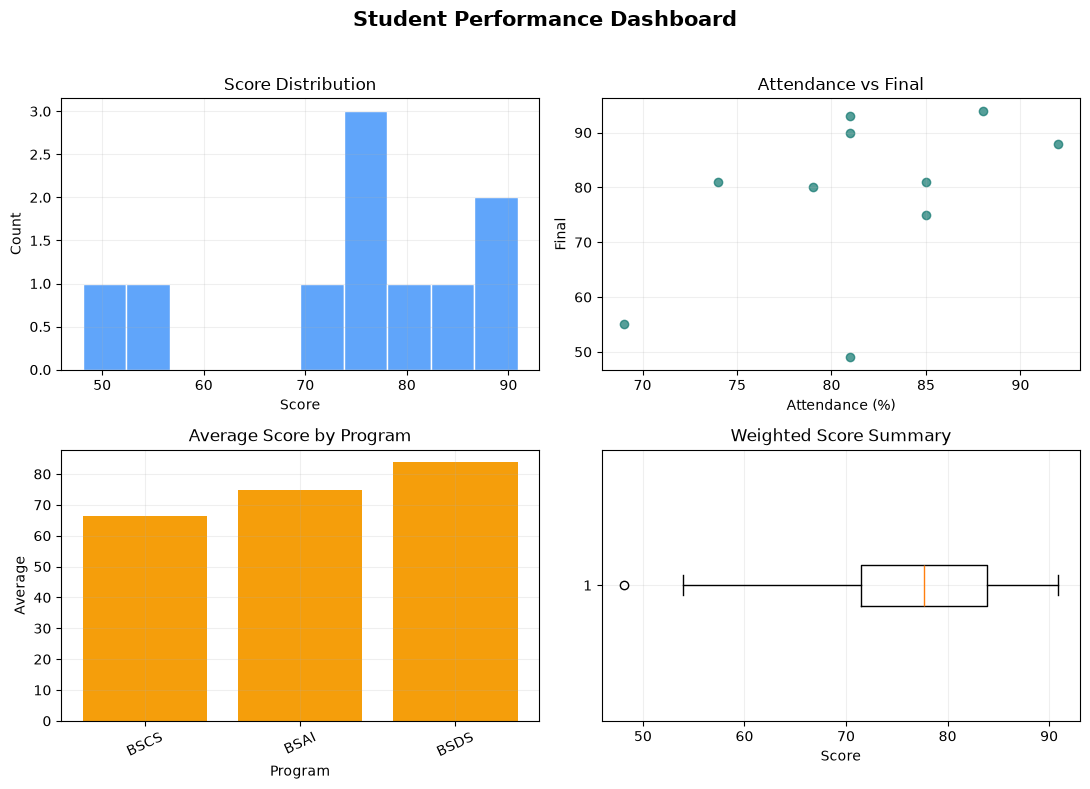

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))

# Top-Left: Histogram
axes[0, 0].hist(students["weighted_score"].dropna(), bins=10, color="#60A5FA", edgecolor="white")
axes[0, 0].set(title="Score Distribution", xlabel="Score", ylabel="Count")

# Top-Right: Scatter Plot
axes[0, 1].scatter(students["attendance"], students["final"], alpha=0.7, color="#0F766E")
axes[0, 1].set(title="Attendance vs Final", xlabel="Attendance (%)", ylabel="Final")

# Bottom-Left: Bar Chart
axes[1, 0].bar(program_scores.index, program_scores.values, color="#F59E0B")
axes[1, 0].set(title="Average Score by Program", xlabel="Program", ylabel="Average")
axes[1, 0].tick_params(axis="x", rotation=25)

# Bottom-Right: Box Plot
axes[1, 1].boxplot(students["weighted_score"].dropna(), vert=False)
axes[1, 1].set(title="Weighted Score Summary", xlabel="Score")

for ax in axes.flat:
    ax.grid(alpha=0.2)

fig.suptitle("Student Performance Dashboard", fontsize=15, fontweight="bold")
fig.tight_layout(rect=[0, 0, 1, 0.96])

# Save outputs
png_path = FIGURE_DIR / "student_dashboard.png"
pdf_path = FIGURE_DIR / "student_dashboard.pdf"

fig.savefig(png_path, dpi=300, bbox_inches="tight")
fig.savefig(pdf_path, bbox_inches="tight")

print("Dashboard successfully saved to 'figures/' folder!")
plt.show() # Isay show bhi kar dega aur save bhi